# Device Fingerprint Stability Analysis

This notebook validates and visualizes data from the stability analysis report using the v4 dataset with expanded hardware attributes.

## Dataset Overview
- **Source**: `2FP_Per_Device.csv` base deviceCode with FP02 = 2
- **Devices**: 3693 devices
- **Groups**: 5 group attributes
- **Individual Attributes**: 32 attributes (Hardware expanded from 2 to 6)


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Rectangle
import warnings
warnings.filterwarnings('ignore')

# Set style
plt.style.use('default')
sns.set_palette("husl")

print("Libraries imported successfully!")


Libraries imported successfully!


In [9]:
# Load the updated data with OS and Browser columns (v6)
df = pd.read_csv('../data/1nFP_Per_Device_10301102.csv')

df.head()


,DeviceCodeID,Hardware_UniqueCount,Graphic_UniqueCount,Audio_UniqueCount,Browser_UniqueCount,Preferences_UniqueCount
0,19868,1,2,1,1,1
1,3746888,1,1,1,1,1
2,14321024,1,1,1,1,1
3,14426927,1,1,1,1,1
4,14431952,1,1,1,1,1


In [10]:
# Define group-level and individual attribute mapping for v6 data
# Note: v6 has OS and Browser columns added, and expanded hardware attributes
group_columns = {
    'Hardware_UniqueCount': 'Hardware_Group',
    'Graphic_UniqueCount': 'Graphic_Group', 
    'Audio_UniqueCount': 'Audio_Group',
    'Browser_UniqueCount': 'Browser_Group',
    'Preferences_UniqueCount': 'Preferences_Group'
}

# Individual attribute mapping (updated for v6 structure)
attribute_mapping = {
    # Hardware attributes (6 total - expanded from v3)
    'Hardware_platformUniqueCount': 'Hardware_platform',
    'Hardware_cpuClassUniqueCount': 'Hardware_cpuClass',
    'Hardware_architectureUniqueCount': 'Hardware_architecture',
    'Hardware_hardwareConcurrencyUniqueCount': 'Hardware_hardwareConcurrency',
    'Hardware_oscpuUniqueCount': 'Hardware_oscpu',
    'Hardware_DeviceMemoryUniqueCount': 'Hardware_deviceMemory',
    
    # Graphic attributes (9 total)
    'Graphic_CanvasUniqueCount': 'Graphic_canvas',
    'Graphic_WebGLBasicUniqueCount': 'Graphic_webglBasics',
    'Graphic_WebGLExtensionUniqueCount': 'Graphic_webglExtensions',
    'Graphic_FontSetUniqueCount': 'Graphic_fonts',
    'Graphic_FontPreferenceUniqueCount': 'Graphic_fontPreferences',
    'Graphic_ScreenResolutionUniqueCount': 'Graphic_screenResolution',
    'Graphic_ScreenFrameRateUniqueCount': 'Graphic_screenFrame',
    'Graphic_ColorDepthUniqueCount': 'Graphic_colorDepth',
    'Graphic_ColorGamutUniqueCount': 'Graphic_colorGamut',
    
    # Audio attributes (2 total)
    'Audio_ContextUniqueCount': 'Audio_audio',
    'Audio_BaseLatencyUniqueCount': 'Audio_audioBaseLatency',
    
    # Browser attributes (7 total)
    'Browser_NameUniqueCount': 'Browser_browserName',
    'Browser_OSNameUniqueCount': 'Browser_osName',
    'Browser_UserAgentUniqueCount': 'Browser_userAgent',
    'Browser_VendorUniqueCount': 'Browser_vendor',
    'Browser_VendorFlavorUniqueCount': 'Browser_vendorFlavor',
    'Browser_PluginUniqueCount': 'Browser_plugin',
    'Browser_PDFViewerUniqueCount': 'Browser_pdfViewer',
    
    # Preferences attributes (8 total)
    'Pref_LanguageUniqueCount': 'Preferences_languages',
    'Pref_TimezoneUniqueCount': 'Preferences_timezone',
    'Pref_TouchSupportUniqueCount': 'Preferences_touchSupport',
    'Pref_SessionStorageUniqueCount': 'Preferences_sessionStorage',
    'Pref_OpenDatabaseUniqueCount': 'Preferences_openDatabase',
    'Pref_LocalStorageUniqueCount': 'Preferences_localStorage',
    'Pref_IndexedDBUniqueCount': 'Preferences_indexedDB',
    'Pref_CookiesEnabledUniqueCount': 'Preferences_cookiesEnabled'
}

# Create datasets for analysis
group_columns_list = list(group_columns.keys())
attribute_columns_list = list(attribute_mapping.keys())

# Use columns 11-16 for individual attributes (skip OS and Browser columns)
df_groups = df[['DeviceCodeID'] + group_columns_list].copy()
# df_attributes = df[['DeviceCodeID'] + attribute_columns_list].copy()



In [11]:
# # Calculate individual attribute instability rates (ONLY - no group-level analysis)
# instability_data = []

# for col in attribute_columns_list:
#     # Count devices with instability (unique count > 1)
#     unstable_devices = (df_attributes[col] > 1).sum()
#     total_devices = len(df_attributes)
#     instability_rate = (unstable_devices / total_devices) * 100
    
#     instability_data.append({
#         'attribute': attribute_mapping[col],
#         'original_column': col,
#         'unstable_devices': unstable_devices,
#         'total_devices': total_devices,
#         'instability_rate': instability_rate
#     })

# # Create DataFrame for individual attribute analysis
# instability_df = pd.DataFrame(instability_data)
# instability_df = instability_df.sort_values('instability_rate', ascending=False)



In [12]:
# # Define categories for individual attributes (updated for v4 data with expanded hardware)
# categories = {
#     'Hardware': ['Hardware_platform', 'Hardware_cpuClass', 'Hardware_architecture', 
#                 'Hardware_hardwareConcurrency', 'Hardware_oscpu', 'Hardware_deviceMemory'],
#     'Graphic': ['Graphic_canvas', 'Graphic_webglBasics', 'Graphic_webglExtensions', 
#                'Graphic_fonts', 'Graphic_fontPreferences', 'Graphic_screenResolution',
#                'Graphic_screenFrame', 'Graphic_colorDepth', 'Graphic_colorGamut'],
#     'Audio': ['Audio_audio', 'Audio_audioBaseLatency'],
#     'Browser': ['Browser_browserName', 'Browser_osName', 'Browser_userAgent', 
#                'Browser_vendor', 'Browser_vendorFlavor', 'Browser_plugin', 'Browser_pdfViewer'],
#     'Preferences': ['Preferences_languages', 'Preferences_timezone', 'Preferences_touchSupport',
#                    'Preferences_sessionStorage', 'Preferences_openDatabase', 
#                    'Preferences_localStorage', 'Preferences_indexedDB', 'Preferences_cookiesEnabled']
# }

# # Calculate category statistics for individual attributes
# category_stats = []

# for category, attributes in categories.items():
#     category_data = instability_df[instability_df['attribute'].isin(attributes)]
    
#     category_stats.append({
#         'category': category,
#         'attribute_count': len(attributes),
#         'avg_instability': category_data['instability_rate'].mean(),
#         'min_instability': category_data['instability_rate'].min(),
#         'max_instability': category_data['instability_rate'].max(),
#         'zero_instability_count': (category_data['instability_rate'] == 0).sum(),
#         'high_instability_count': (category_data['instability_rate'] > 10).sum()
#     })

# category_df = pd.DataFrame(category_stats)
# category_df = category_df.sort_values('avg_instability')


# # Add category information to instability_df
# instability_df['category'] = instability_df['attribute'].apply(
#     lambda x: next((cat for cat, attrs in categories.items() if x in attrs), 'Unknown')
# )



In [13]:
# Calculate GROUP instability rates (not individual attributes)
group_instability_data = []

for col in group_columns_list:
    # Count devices with instability (unique count > 1)
    unstable_devices = (df_groups[col] > 1).sum()
    total_devices = len(df_groups)
    instability_rate = (unstable_devices / total_devices) * 100
    
    group_instability_data.append({
        'group': group_columns[col],
        'original_column': col,
        'unstable_devices': unstable_devices,
        'total_devices': total_devices,
        'instability_rate': instability_rate
    })

# Create DataFrame for group analysis
group_instability_df = pd.DataFrame(group_instability_data)
group_instability_df = group_instability_df.sort_values('instability_rate', ascending=False)

print("GROUP Instability Analysis (v7 - Direct Group Analysis):")
print("=" * 60)
print(f"Total devices analyzed: {total_devices}")
print(f"Total groups: {len(group_columns_list)}")
print(f"Average group instability rate: {group_instability_df['instability_rate'].mean():.1f}%")
print("\nGroup Instability Rates:")
print(group_instability_df[['group', 'unstable_devices', 'instability_rate']].to_string(index=False))


GROUP Instability Analysis (v7 - Direct Group Analysis):
Total devices analyzed: 107511
Total groups: 5
Average group instability rate: 0.9%

Group Instability Rates:
            group  unstable_devices  instability_rate
    Graphic_Group              2191          2.037931
    Browser_Group              1208          1.123606
      Audio_Group               901          0.838054
Preferences_Group               514          0.478091
   Hardware_Group                82          0.076271


## CHART 1 ANALYSIS - GROUP INSTABILITY

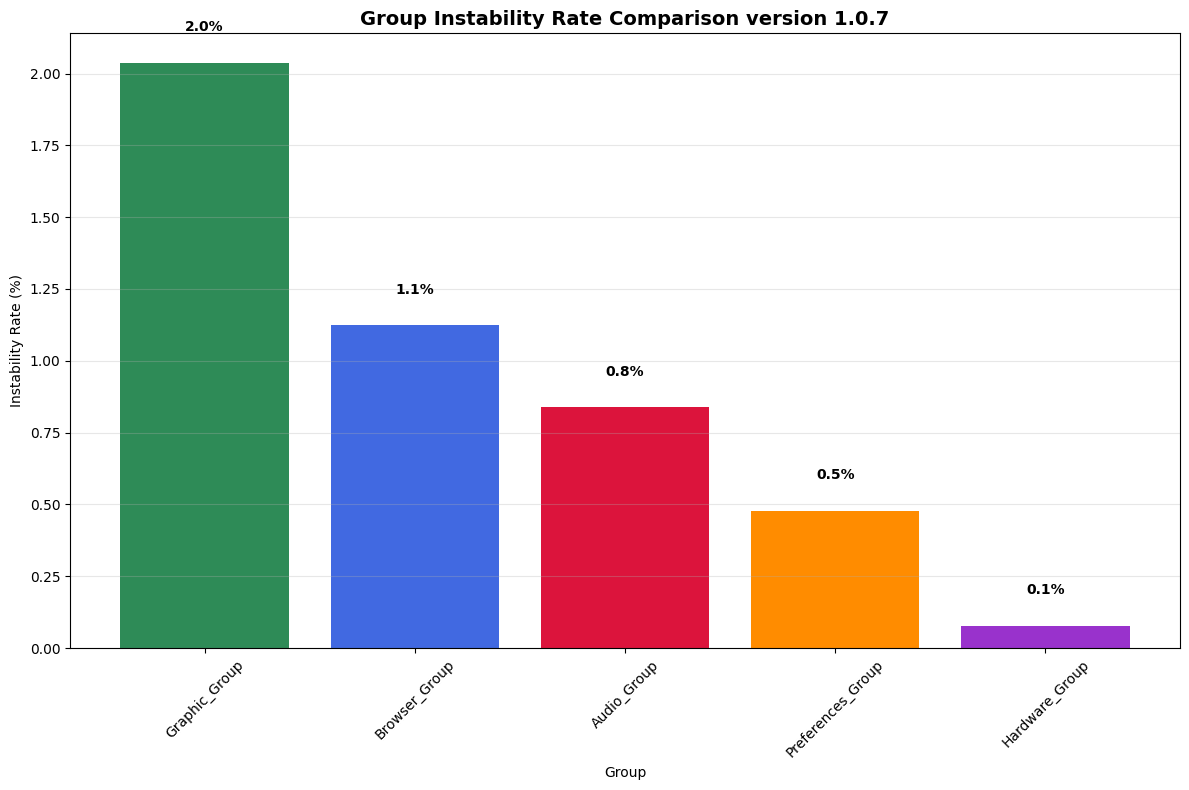

CHART 1 ANALYSIS - GROUP INSTABILITY
Group instability ranking:
1. Graphic_Group: 2.0% (2191 devices)
2. Browser_Group: 1.1% (1208 devices)
3. Audio_Group: 0.8% (901 devices)
4. Preferences_Group: 0.5% (514 devices)
5. Hardware_Group: 0.1% (82 devices)

Average group instability: 0.9%

CONCLUSION: Direct group analysis shows the actual instability rates for each group category.


In [14]:
# Chart 1: Group Comparison (Direct Group Analysis)
plt.figure(figsize=(12, 8))
bars = plt.bar(group_instability_df['group'], group_instability_df['instability_rate'], 
               color=['#2E8B57', '#4169E1', '#DC143C', '#FF8C00', '#9932CC'])

# Add value labels on bars
for i, bar in enumerate(bars):
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 0.1,
             f'{height:.1f}%', ha='center', va='bottom', fontweight='bold')

plt.xlabel('Group')
plt.ylabel('Instability Rate (%)')
plt.title('Group Instability Rate Comparison version 1.0.7', fontsize=14, fontweight='bold')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

print("CHART 1 ANALYSIS - GROUP INSTABILITY")
print("=" * 40)
print("Group instability ranking:")
for i, (_, row) in enumerate(group_instability_df.iterrows(), 1):
    print(f"{i}. {row['group']}: {row['instability_rate']:.1f}% ({row['unstable_devices']} devices)")
print(f"\nAverage group instability: {group_instability_df['instability_rate'].mean():.1f}%")
print("\nCONCLUSION: Direct group analysis shows the actual instability rates for each group category.")


## Chart 2: Top 10 Most Unstable Attributes


In [15]:
# Chart 3: Top 10 Most Unstable Attributes
top_unstable = instability_df.head(10)

plt.figure(figsize=(14, 8))
bars = plt.barh(range(len(top_unstable)), top_unstable['instability_rate'], 
               color='coral', alpha=0.8)

# Add value labels
for i, bar in enumerate(bars):
    width = bar.get_width()
    plt.text(width + 0.1, bar.get_y() + bar.get_height()/2,
             f'{width:.1f}%', ha='left', va='center', fontweight='bold')

plt.yticks(range(len(top_unstable)), [attr.split('_')[1] for attr in top_unstable['attribute']])
plt.xlabel('Instability Rate (%)')
plt.title('Top 10 Most Unstable Attributes - version 1.0.7', fontsize=14, fontweight='bold')
plt.grid(True, alpha=0.3, axis='x')
plt.tight_layout()
plt.show()

print("CHART 2 ANALYSIS")
print("=" * 20)
print("Top 10 most unstable attributes:")
for i, (_, row) in enumerate(top_unstable.iterrows(), 1):
    print(f"{i}. {row['attribute']}: {row['instability_rate']:.1f}% ({row['unstable_devices']} devices)")
print("\nCONCLUSION: Graphic attributes dominate the most unstable list, indicating potential anti-fingerprinting measures.")


NameError: name 'instability_df' is not defined

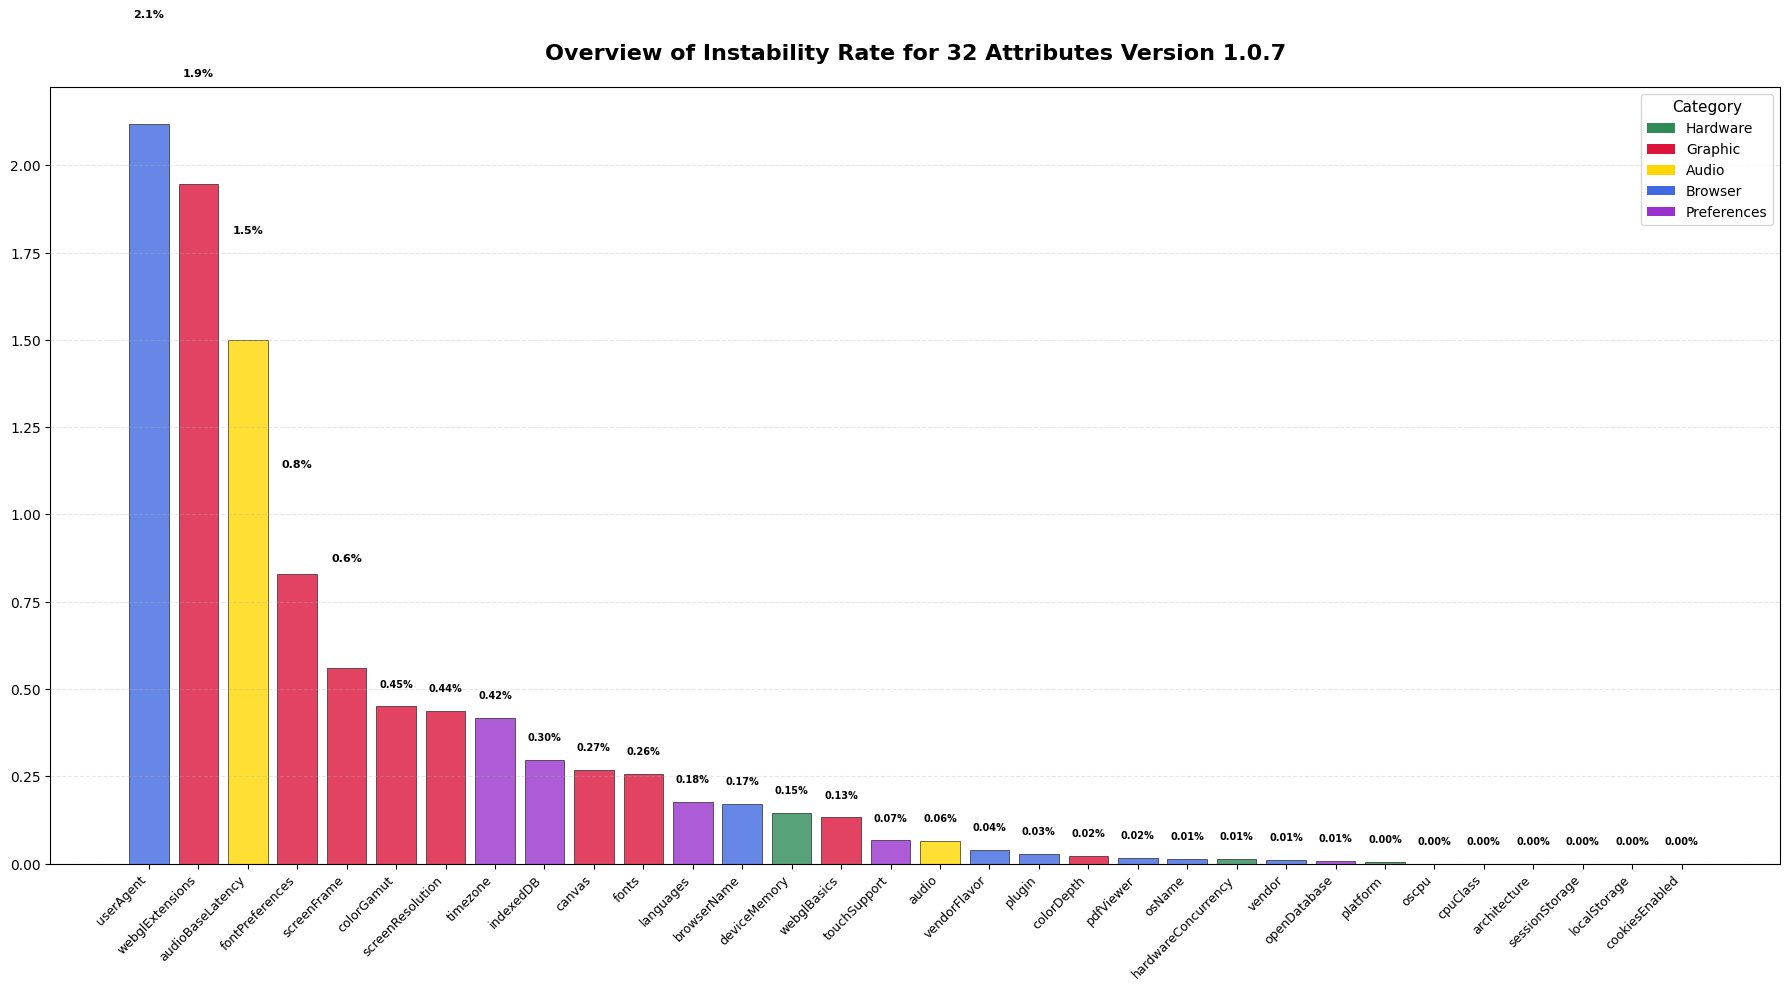

OVERVIEW OF 32 ATTRIBUTES - INSTABILITY RATE

Total attributes: 32
Average instability rate: 0.31%
Highest instability rate: 2.12% (Browser_userAgent)
Lowest instability rate: 0.00%

Distribution by Category:
------------------------------------------------------------
Hardware       :  6 attributes | Average:  0.03% | Min:  0.00% | Max:  0.15%
Graphic        :  9 attributes | Average:  0.54% | Min:  0.02% | Max:  1.95%
Audio          :  2 attributes | Average:  0.78% | Min:  0.06% | Max:  1.50%
Browser        :  7 attributes | Average:  0.34% | Min:  0.01% | Max:  2.12%
Preferences    :  8 attributes | Average:  0.12% | Min:  0.00% | Max:  0.42%


In [ ]:
# Chart: Biểu đồ cột tổng quan cho tất cả 32 Attributes
# Sắp xếp theo instability rate giảm dần để dễ nhìn
instability_df_sorted = instability_df.sort_values('instability_rate', ascending=False).copy()

# Định nghĩa màu sắc cho từng category
category_colors = {
    'Hardware': '#2E8B57',      # Sea Green
    'Graphic': '#DC143C',       # Crimson
    'Audio': '#FFD700',         # Gold
    'Browser': '#4169E1',       # Royal Blue
    'Preferences': '#9932CC'    # Dark Orchid
}

# Tạo màu cho từng attribute dựa trên category
colors = [category_colors.get(cat, '#808080') for cat in instability_df_sorted['category']]

# Tạo biểu đồ
fig, ax = plt.subplots(figsize=(18, 10))

# Vẽ biểu đồ cột
bars = ax.bar(range(len(instability_df_sorted)), 
              instability_df_sorted['instability_rate'],
              color=colors, 
              alpha=0.8,
              edgecolor='black',
              linewidth=0.5)

# Thêm giá trị trên mỗi cột
for i, (bar, rate) in enumerate(zip(bars, instability_df_sorted['instability_rate'])):
    if rate > 0.5:  # Chỉ hiển thị label nếu giá trị > 0.5%
        ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.3,
               f'{rate:.1f}%', 
               ha='center', va='bottom', 
               fontsize=8, fontweight='bold')
    else:
        ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.05,
               f'{rate:.2f}%', 
               ha='center', va='bottom', 
               fontsize=7, fontweight='bold')

# Cấu hình trục x
ax.set_xticks(range(len(instability_df_sorted)))
ax.set_xticklabels([attr.split('_')[1] if '_' in attr else attr 
                   for attr in instability_df_sorted['attribute']], 
                  rotation=45, ha='right', fontsize=9)

ax.grid(True, alpha=0.3, axis='y', linestyle='--')

# Tạo legend cho categories
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=color, label=cat) 
                   for cat, color in category_colors.items()]
ax.legend(handles=legend_elements, loc='upper right', fontsize=10, title='Category', title_fontsize=11)
ax.set_title('Overview of Instability Rate for 32 Attributes Version 1.0.7', 
            fontsize=16, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

# Print summary statistics
print("=" * 80)
print("OVERVIEW OF 32 ATTRIBUTES - INSTABILITY RATE")
print("=" * 80)
print(f"\nTotal attributes: {len(instability_df_sorted)}")
print(f"Average instability rate: {instability_df_sorted['instability_rate'].mean():.2f}%")
print(f"Highest instability rate: {instability_df_sorted['instability_rate'].max():.2f}% ({instability_df_sorted.iloc[0]['attribute']})")
print(f"Lowest instability rate: {instability_df_sorted['instability_rate'].min():.2f}%")

print("\nDistribution by Category:")
print("-" * 60)
for category in ['Hardware', 'Graphic', 'Audio', 'Browser', 'Preferences']:
    cat_data = instability_df_sorted[instability_df_sorted['category'] == category]
    if len(cat_data) > 0:
        print(f"{category:15s}: {len(cat_data):2d} attributes | "
              f"Average: {cat_data['instability_rate'].mean():5.2f}% | "
              f"Min: {cat_data['instability_rate'].min():5.2f}% | "
              f"Max: {cat_data['instability_rate'].max():5.2f}%")


## Chart 3: Stability Classification Distribution



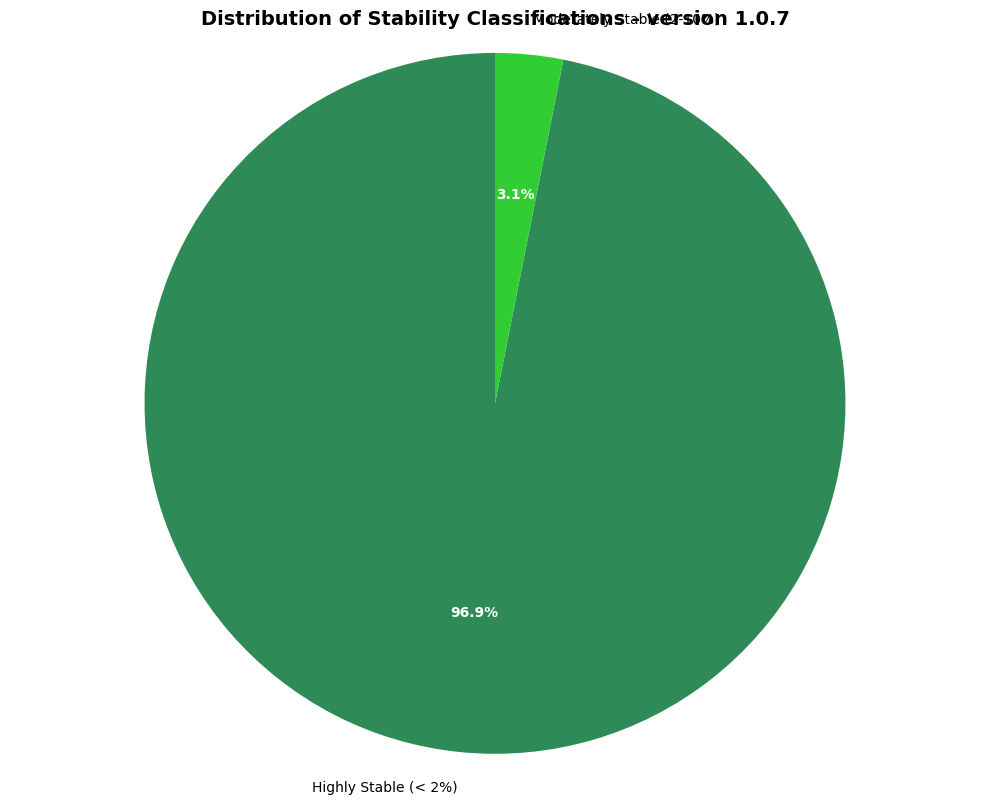

CHART 3 ANALYSIS
Stability classification distribution:
• Highly Stable (< 2%): 31 attributes (96.9%)
• Moderately Stable (2-10%): 1 attributes (3.1%)

CONCLUSION: Most attributes fall into the 'Highly Stable' category, indicating good overall stability.


In [ ]:
# Chart 4: Stability Classification Distribution
# Define stability categories
def classify_stability(rate):
    if rate < 2:
        return 'Highly Stable (< 2%)'
    elif rate < 10:
        return 'Moderately Stable (2-10%)'
    elif rate < 30:
        return 'Unstable (10-30%)'
    else:
        return 'Highly Unstable (> 30%)'

instability_df['stability_class'] = instability_df['instability_rate'].apply(classify_stability)
stability_counts = instability_df['stability_class'].value_counts()

plt.figure(figsize=(10, 8))
colors = ['#2E8B57', '#32CD32', '#FFD700', '#FF6347']
wedges, texts, autotexts = plt.pie(stability_counts.values, labels=stability_counts.index, 
                                  autopct='%1.1f%%', colors=colors, startangle=90)

# Enhance text
for autotext in autotexts:
    autotext.set_color('white')
    autotext.set_fontweight('bold')

plt.title('Distribution of Stability Classifications - version 1.0.7', fontsize=14, fontweight='bold')
plt.axis('equal')
plt.tight_layout()
plt.show()

print("CHART 3 ANALYSIS")
print("=" * 20)
print("Stability classification distribution:")
for class_name, count in stability_counts.items():
    percentage = (count / len(instability_df)) * 100
    print(f"• {class_name}: {count} attributes ({percentage:.1f}%)")
print("\nCONCLUSION: Most attributes fall into the 'Highly Stable' category, indicating good overall stability.")


## Chart 4: Hardware Category Analysis


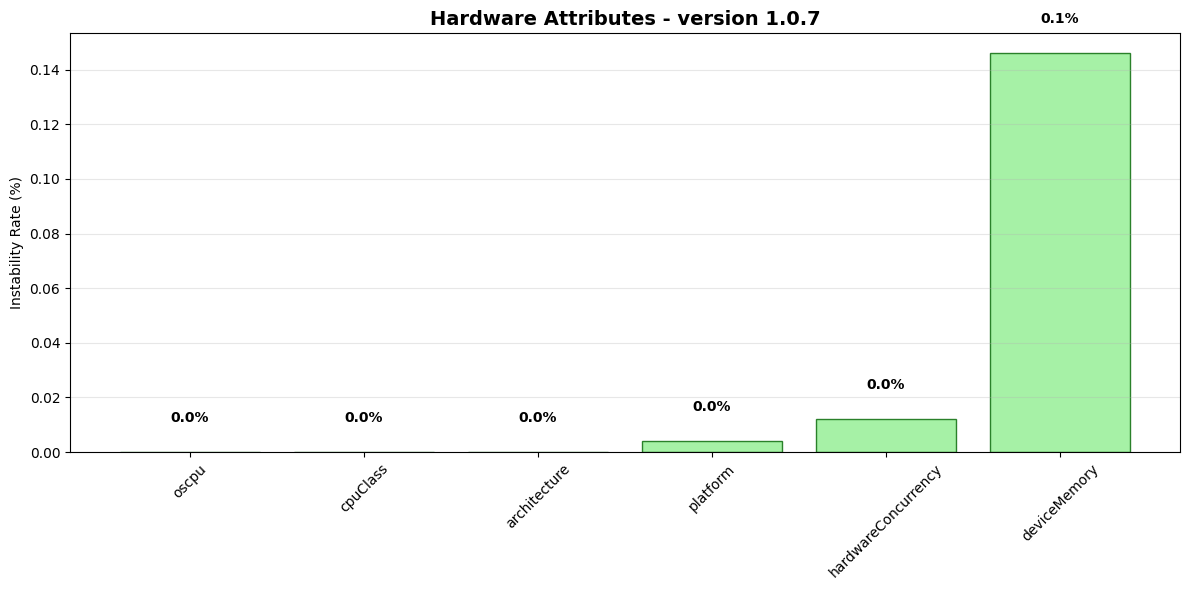

CHART 4 ANALYSIS
Hardware attributes (expanded from 2 to 6 in v4):
1. Hardware_oscpu: 0.0% (0 devices)
2. Hardware_cpuClass: 0.0% (0 devices)
3. Hardware_architecture: 0.0% (0 devices)
4. Hardware_platform: 0.0% (2 devices)
5. Hardware_hardwareConcurrency: 0.0% (6 devices)
6. Hardware_deviceMemory: 0.1% (73 devices)

Average hardware instability: 0.0%

CONCLUSION: Hardware attributes remain highly stable even with expansion to 6 attributes in v4.


In [ ]:
# Chart 5: Hardware Category Analysis (expanded in v4)
hardware_data = instability_df[instability_df['category'] == 'Hardware'].sort_values('instability_rate')

plt.figure(figsize=(12, 6))
bars = plt.bar(range(len(hardware_data)), hardware_data['instability_rate'], 
               color='lightgreen', alpha=0.8, edgecolor='darkgreen')

# Add value labels
for i, bar in enumerate(bars):
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 0.01,
             f'{height:.1f}%', ha='center', va='bottom', fontweight='bold')

plt.xticks(range(len(hardware_data)), [attr.split('_')[1] for attr in hardware_data['attribute']], rotation=45)
plt.ylabel('Instability Rate (%)')
plt.title('Hardware Attributes - version 1.0.7', fontsize=14, fontweight='bold')
plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

print("CHART 4 ANALYSIS")
print("=" * 20)
print("Hardware attributes (expanded from 2 to 6 in v4):")
for i, (_, row) in enumerate(hardware_data.iterrows(), 1):
    print(f"{i}. {row['attribute']}: {row['instability_rate']:.1f}% ({row['unstable_devices']} devices)")
print(f"\nAverage hardware instability: {hardware_data['instability_rate'].mean():.1f}%")
print("\nCONCLUSION: Hardware attributes remain highly stable even with expansion to 6 attributes in v4.")


## Chart 5: Graphic Category Analysis


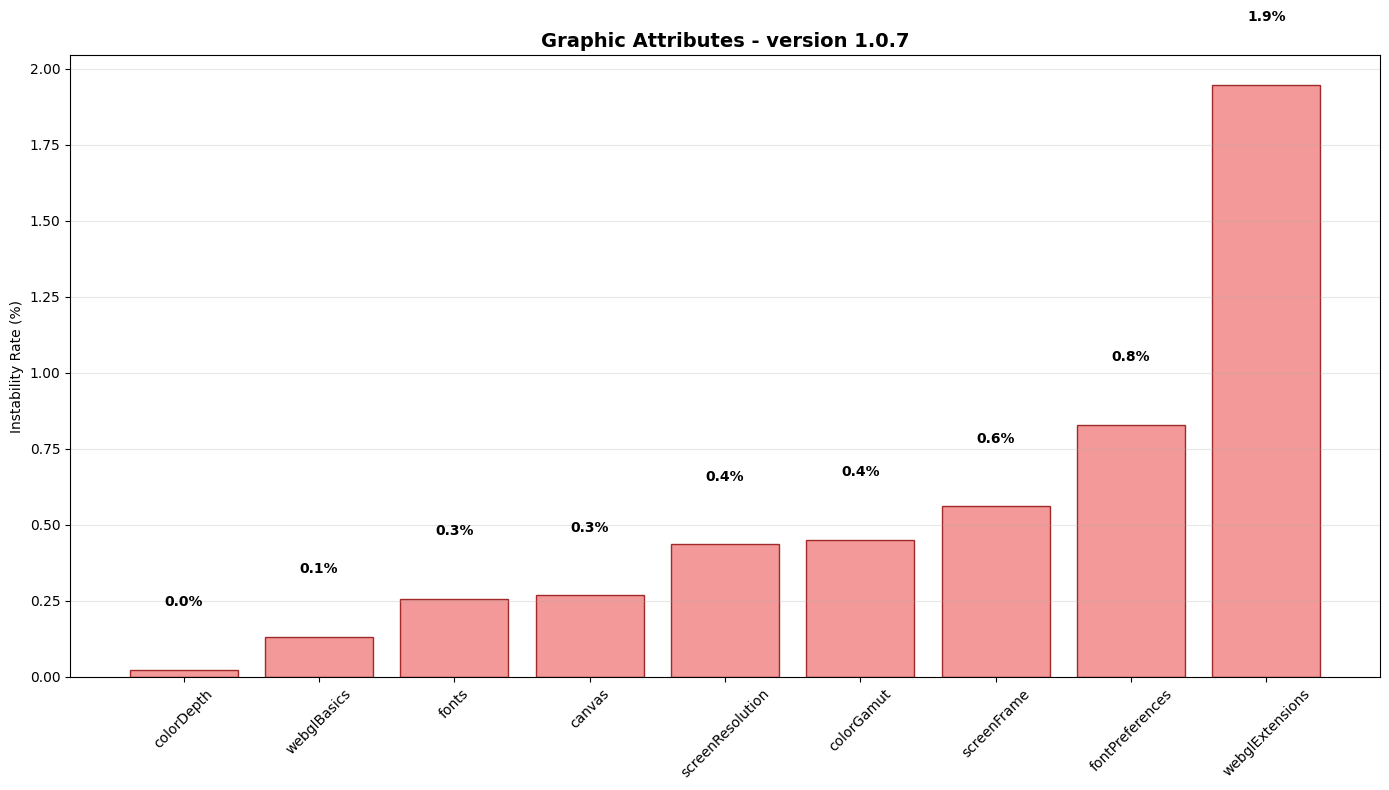

CHART 5 ANALYSIS
Graphic attributes instability:
1. Graphic_colorDepth: 0.0% (11 devices)
2. Graphic_webglBasics: 0.1% (66 devices)
3. Graphic_fonts: 0.3% (128 devices)
4. Graphic_canvas: 0.3% (134 devices)
5. Graphic_screenResolution: 0.4% (218 devices)
6. Graphic_colorGamut: 0.4% (225 devices)
7. Graphic_screenFrame: 0.6% (280 devices)
8. Graphic_fontPreferences: 0.8% (414 devices)
9. Graphic_webglExtensions: 1.9% (974 devices)

Average graphic instability: 0.5%

CONCLUSION: Graphic attributes show concerning instability patterns, likely due to anti-fingerprinting measures.


In [ ]:
# Chart 6: Graphic Category Analysis
graphic_data = instability_df[instability_df['category'] == 'Graphic'].sort_values('instability_rate')

plt.figure(figsize=(14, 8))
bars = plt.bar(range(len(graphic_data)), graphic_data['instability_rate'], 
               color='lightcoral', alpha=0.8, edgecolor='darkred')

# Add value labels
for i, bar in enumerate(bars):
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 0.2,
             f'{height:.1f}%', ha='center', va='bottom', fontweight='bold')

plt.xticks(range(len(graphic_data)), [attr.split('_')[1] for attr in graphic_data['attribute']], rotation=45)
plt.ylabel('Instability Rate (%)')
plt.title('Graphic Attributes - version 1.0.7', fontsize=14, fontweight='bold')
plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

print("CHART 5 ANALYSIS")
print("=" * 20)
print("Graphic attributes instability:")
for i, (_, row) in enumerate(graphic_data.iterrows(), 1):
    print(f"{i}. {row['attribute']}: {row['instability_rate']:.1f}% ({row['unstable_devices']} devices)")
print(f"\nAverage graphic instability: {graphic_data['instability_rate'].mean():.1f}%")
print("\nCONCLUSION: Graphic attributes show concerning instability patterns, likely due to anti-fingerprinting measures.")


## Chart 6: Browser Category Analysis


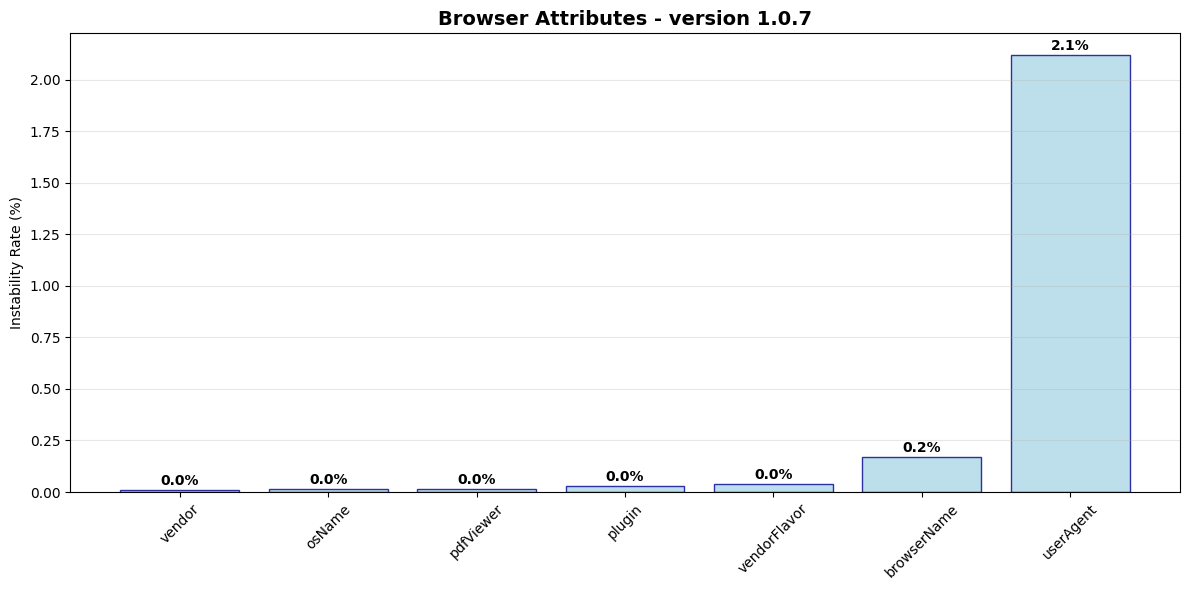

CHART 6 ANALYSIS
Browser attributes instability:
1. Browser_vendor: 0.0% (5 devices)
2. Browser_osName: 0.0% (7 devices)
3. Browser_pdfViewer: 0.0% (8 devices)
4. Browser_plugin: 0.0% (14 devices)
5. Browser_vendorFlavor: 0.0% (19 devices)
6. Browser_browserName: 0.2% (85 devices)
7. Browser_userAgent: 2.1% (1059 devices)

Average browser instability: 0.3%

CONCLUSION: Browser attributes show good stability, making them reliable for device identification.


In [ ]:
# Chart 7: Browser Category Analysis
browser_data = instability_df[instability_df['category'] == 'Browser'].sort_values('instability_rate')

plt.figure(figsize=(12, 6))
bars = plt.bar(range(len(browser_data)), browser_data['instability_rate'], 
               color='lightblue', alpha=0.8, edgecolor='darkblue')

# Add value labels
for i, bar in enumerate(bars):
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 0.01,
             f'{height:.1f}%', ha='center', va='bottom', fontweight='bold')

plt.xticks(range(len(browser_data)), [attr.split('_')[1] for attr in browser_data['attribute']], rotation=45)
plt.ylabel('Instability Rate (%)')
plt.title('Browser Attributes - version 1.0.7', fontsize=14, fontweight='bold')
plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

print("CHART 6 ANALYSIS")
print("=" * 20)
print("Browser attributes instability:")
for i, (_, row) in enumerate(browser_data.iterrows(), 1):
    print(f"{i}. {row['attribute']}: {row['instability_rate']:.1f}% ({row['unstable_devices']} devices)")
print(f"\nAverage browser instability: {browser_data['instability_rate'].mean():.1f}%")
print("\nCONCLUSION: Browser attributes show good stability, making them reliable for device identification.")


## Chart 7: Preferences Category Analysis


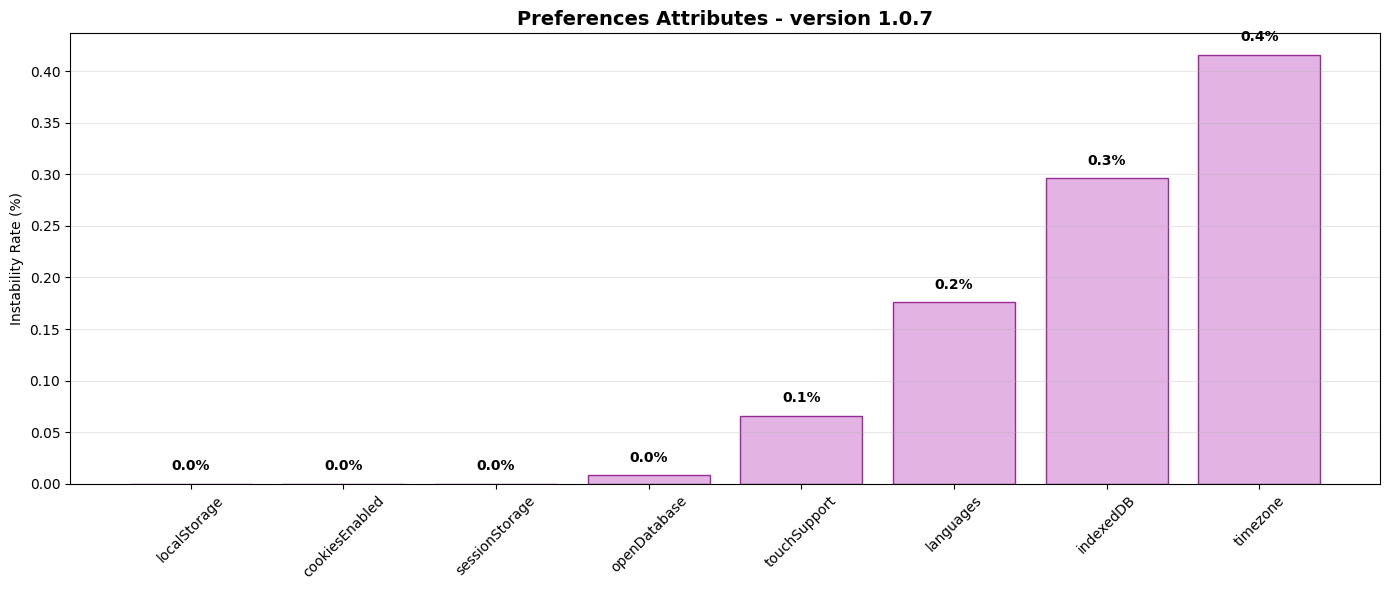

CHART 7 ANALYSIS
Preferences attributes instability:
1. Preferences_localStorage: 0.0% (0 devices)
2. Preferences_cookiesEnabled: 0.0% (0 devices)
3. Preferences_sessionStorage: 0.0% (0 devices)
4. Preferences_openDatabase: 0.0% (4 devices)
5. Preferences_touchSupport: 0.1% (33 devices)
6. Preferences_languages: 0.2% (88 devices)
7. Preferences_indexedDB: 0.3% (148 devices)
8. Preferences_timezone: 0.4% (208 devices)

Average preferences instability: 0.1%

CONCLUSION: Preferences attributes show moderate stability, suitable for device identification.


In [ ]:
# Chart 8: Preferences Category Analysis
preferences_data = instability_df[instability_df['category'] == 'Preferences'].sort_values('instability_rate')

plt.figure(figsize=(14, 6))
bars = plt.bar(range(len(preferences_data)), preferences_data['instability_rate'], 
               color='plum', alpha=0.8, edgecolor='purple')

# Add value labels
for i, bar in enumerate(bars):
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 0.01,
             f'{height:.1f}%', ha='center', va='bottom', fontweight='bold')

plt.xticks(range(len(preferences_data)), [attr.split('_')[1] for attr in preferences_data['attribute']], rotation=45)
plt.ylabel('Instability Rate (%)')
plt.title('Preferences Attributes - version 1.0.7', fontsize=14, fontweight='bold')
plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

print("CHART 7 ANALYSIS")
print("=" * 20)
print("Preferences attributes instability:")
for i, (_, row) in enumerate(preferences_data.iterrows(), 1):
    print(f"{i}. {row['attribute']}: {row['instability_rate']:.1f}% ({row['unstable_devices']} devices)")
print(f"\nAverage preferences instability: {preferences_data['instability_rate'].mean():.1f}%")
print("\nCONCLUSION: Preferences attributes show moderate stability, suitable for device identification.")


## Chart 8: Audio Category Analysis


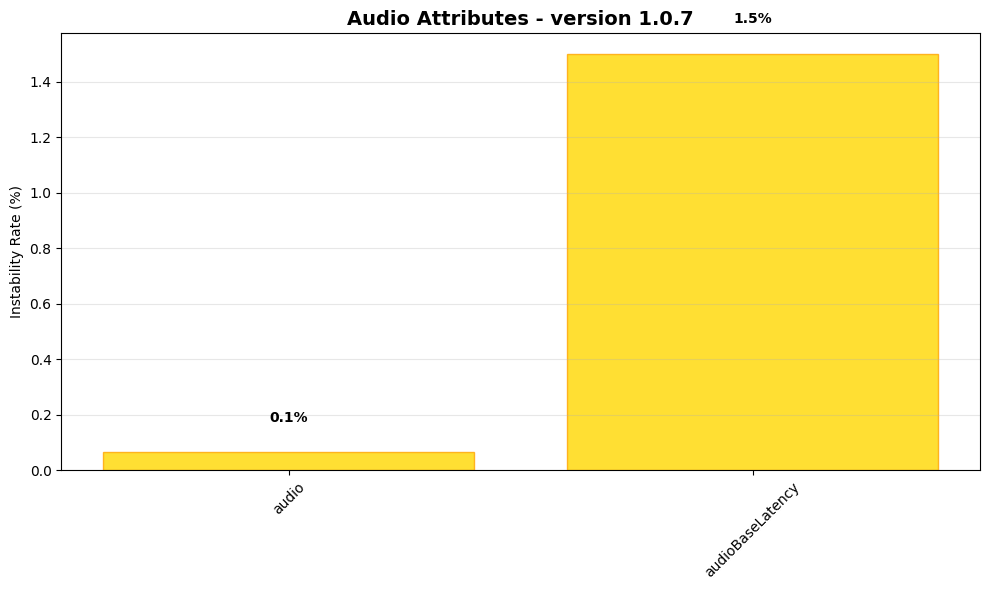

CHART 8 ANALYSIS
Audio attributes instability:
1. Audio_audio: 0.1% (32 devices)
2. Audio_audioBaseLatency: 1.5% (750 devices)

Average audio instability: 0.8%

CONCLUSION: Audio attributes show moderate stability with some variability.


In [ ]:
# Chart 9: Audio Category Analysis
audio_data = instability_df[instability_df['category'] == 'Audio'].sort_values('instability_rate')

plt.figure(figsize=(10, 6))
bars = plt.bar(range(len(audio_data)), audio_data['instability_rate'], 
               color='gold', alpha=0.8, edgecolor='orange')

# Add value labels
for i, bar in enumerate(bars):
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 0.1,
             f'{height:.1f}%', ha='center', va='bottom', fontweight='bold')

plt.xticks(range(len(audio_data)), [attr.split('_')[1] for attr in audio_data['attribute']], rotation=45)
plt.ylabel('Instability Rate (%)')
plt.title('Audio Attributes - version 1.0.7', fontsize=14, fontweight='bold')
plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

print("CHART 8 ANALYSIS")
print("=" * 20)
print("Audio attributes instability:")
for i, (_, row) in enumerate(audio_data.iterrows(), 1):
    print(f"{i}. {row['attribute']}: {row['instability_rate']:.1f}% ({row['unstable_devices']} devices)")
print(f"\nAverage audio instability: {audio_data['instability_rate'].mean():.1f}%")
print("\nCONCLUSION: Audio attributes show moderate stability with some variability.")


In [ ]:
# Chart: OS-Browser Heatmap (v7 Data)
# First, create the expanded dataset
print("Creating expanded dataset...")

# Get OS and Browser columns
os_col = df.columns[9]  # OS_List
browser_col = df.columns[10]  # Browser_List

# Create expanded dataset with individual OS-Browser combinations
expanded_rows = []

for idx, row in df.iterrows():
    device_id = row['DeviceCodeID']
    
    # Split OS values
    os_values = str(row[os_col]).split(',') if pd.notna(row[os_col]) else ['Unknown']
    os_values = [os.strip() for os in os_values if os.strip()]
    
    # Split Browser values  
    browser_values = str(row[browser_col]).split(',') if pd.notna(row[browser_col]) else ['Unknown']
    browser_values = [browser.strip() for browser in browser_values if browser.strip()]
    
    # Create all combinations of OS and Browser for this device
    for os_val in os_values:
        for browser_val in browser_values:
            expanded_row = row.copy()
            expanded_row['OS_Single'] = os_val
            expanded_row['Browser_Single'] = browser_val
            expanded_row['OS_Browser'] = f"{os_val} + {browser_val}"
            expanded_rows.append(expanded_row)

# Create expanded DataFrame
df_expanded = pd.DataFrame(expanded_rows)
print(f"✅ Expanded dataset created: {len(df_expanded)} OS-Browser combinations")

fig, ax = plt.subplots(figsize=(16, 10))

# Create OS-Browser cross-tabulation for heatmap
os_browser_matrix = pd.crosstab(df_expanded['OS_Single'], df_expanded['Browser_Single'])

# Create heatmap
im = ax.imshow(os_browser_matrix.values, cmap='YlGnBu', aspect='auto',)

# Set labels
ax.set_yticks(range(len(os_browser_matrix.index)))
ax.set_yticklabels(os_browser_matrix.index)
ax.set_xticks(range(len(os_browser_matrix.columns)))
ax.set_xticklabels(os_browser_matrix.columns, rotation=45, ha='right')

for i in range(len(os_browser_matrix.index)):
    for j in range(len(os_browser_matrix.columns)):
        count = os_browser_matrix.iloc[i, j]
        pct = os_browser_pct.iloc[i, j]
        if count > 0:
            text_color = 'white' if count > os_browser_matrix.values.max() * 0.6 else 'black'
            ax.text(j, i, f'{count}\n({pct:.1f}%)',
                    ha='center', va='center', color=text_color, fontsize=8, fontweight='bold')


# Add colorbar
cbar = plt.colorbar(im, ax=ax)
cbar.set_label('Number of Devices', rotation=270, labelpad=20)

# Add text annotations
for i in range(len(os_browser_matrix.index)):
    for j in range(len(os_browser_matrix.columns)):
        text = ax.text(j, i, os_browser_matrix.iloc[i, j],
                      ha="center", va="center", color="black", fontsize=10, fontweight='bold')

ax.set_title('OS-Browser Device Distribution Heatmap (v7)', fontsize=16, fontweight='bold')
ax.set_xlabel('Browser', fontsize=12)
ax.set_ylabel('Operating System', fontsize=12)
plt.tight_layout()
plt.show()

Creating expanded dataset...


IndexError: index 9 is out of bounds for axis 0 with size 6

Top OS-Browser combinations for group analysis (min 5 occurrences):
  Android + Chrome Mobile: 1256 occurrences
  iOS + Mobile Safari: 1150 occurrences
  Windows + Chrome: 700 occurrences
  iOS + Chrome Mobile iOS: 289 occurrences
  Windows + Firefox: 169 occurrences
  Android + Chrome: 137 occurrences
  Android + Samsung Internet: 129 occurrences
  Windows + Edge: 86 occurrences
  Mac OS X + Safari: 78 occurrences
  iOS + Google: 75 occurrences


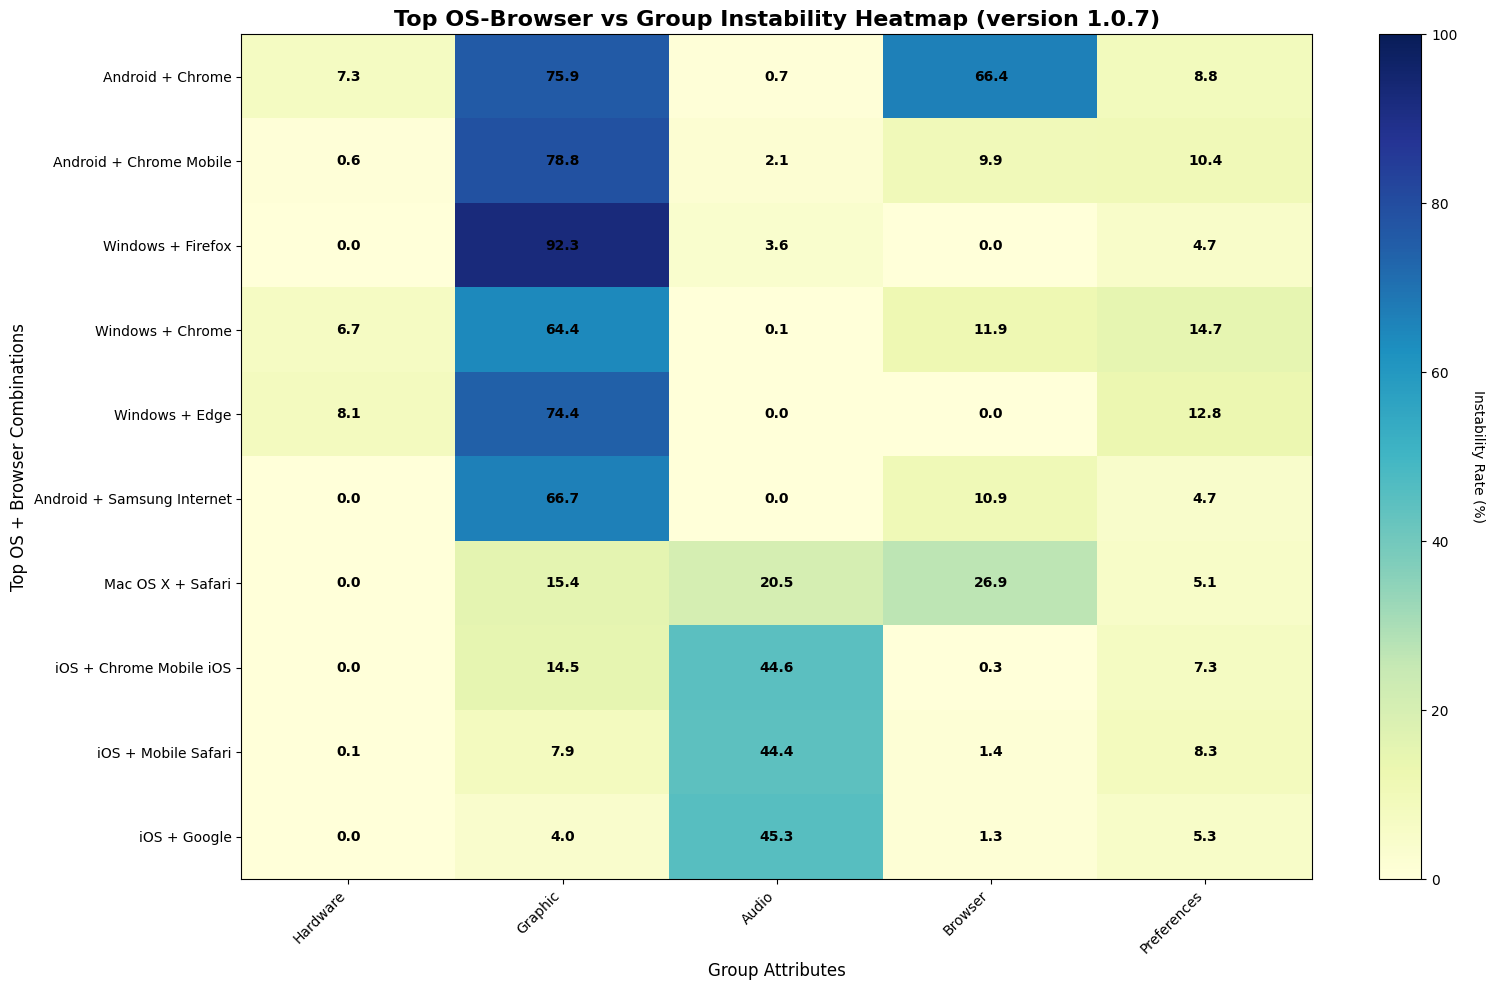

TOP OS-BROWSER vs GROUP INSTABILITY ANALYSIS (version 1.0.7)
Heatmap shows instability rates for top OS-Browser combinations:
Total top OS-Browser combinations: 10
Group attributes analyzed: 5
Minimum occurrences per combination: 5

Most stable top OS-Browser combination: iOS + Google
  Average instability: 56.0%

Most unstable top OS-Browser combination: Android + Chrome
  Average instability: 159.1%

CONCLUSION: Expanded analysis reveals instability patterns across true OS-Browser combinations, accounting for devices using multiple OS/Browser types.


In [ ]:
# Chart: Top OS-Browser vs Group Instability Heatmap (v7 Data - Expanded)
fig, ax = plt.subplots(figsize=(16, 10))

# Create df_expanded if not exists
if 'df_expanded' not in globals():
    print("Creating expanded dataset...")
    
    # Get OS and Browser columns
    os_col = df.columns[9]  # OS_List
    browser_col = df.columns[10]  # Browser_List
    
    # Create expanded dataset with individual OS-Browser combinations
    expanded_rows = []
    
    for idx, row in df.iterrows():
        device_id = row['DeviceCodeID']
        
        # Split OS values
        os_values = str(row[os_col]).split(',') if pd.notna(row[os_col]) else ['Unknown']
        os_values = [os.strip() for os in os_values if os.strip()]
        
        # Split Browser values  
        browser_values = str(row[browser_col]).split(',') if pd.notna(row[browser_col]) else ['Unknown']
        browser_values = [browser.strip() for browser in browser_values if browser.strip()]
        
        # Create all combinations of OS and Browser for this device
        for os_val in os_values:
            for browser_val in browser_values:
                expanded_row = row.copy()
                expanded_row['OS_Single'] = os_val
                expanded_row['Browser_Single'] = browser_val
                expanded_row['OS_Browser'] = f"{os_val} + {browser_val}"
                expanded_rows.append(expanded_row)
    
    # Create expanded DataFrame
    df_expanded = pd.DataFrame(expanded_rows)
    print(f"✅ Expanded dataset created: {len(df_expanded)} OS-Browser combinations")

# Define group columns
group_columns = {
    'Hardware_UniqueCount': 'Hardware_Group',
    'Graphic_UniqueCount': 'Graphic_Group', 
    'Audio_UniqueCount': 'Audio_Group',
    'Browser_UniqueCount': 'Browser_Group',
    'Preferences_UniqueCount': 'Preferences_Group'
}
group_columns_list = list(group_columns.keys())

# Get top OS-Browser combinations by occurrence count (minimum 5 occurrences)
os_browser_counts = df_expanded['OS_Browser'].value_counts()
top_os_browser = os_browser_counts[os_browser_counts >= 5].head(10)  # Top 10 with at least 5 occurrences

print(f"Top OS-Browser combinations for group analysis (min 5 occurrences):")
for combo, count in top_os_browser.items():
    print(f"  {combo}: {count} occurrences")

# Calculate average group instability for top OS-Browser combinations only
group_instability_by_os_browser = []

for os_browser in top_os_browser.index:
    subset = df_expanded[df_expanded['OS_Browser'] == os_browser]
    
    # Calculate average instability for each group
    group_stats = {}
    for group_col in group_columns_list:
        # Count occurrences with instability (unique count > 1)
        unstable_occurrences = (subset[group_col] > 1).sum()
        total_occurrences = len(subset)
        instability_rate = (unstable_occurrences / total_occurrences) * 100 if total_occurrences > 0 else 0
        group_stats[group_col] = instability_rate
    
    group_instability_by_os_browser.append({
        'OS_Browser': os_browser,
        **group_stats
    })

# Create DataFrame for heatmap
heatmap_df = pd.DataFrame(group_instability_by_os_browser)
heatmap_df = heatmap_df.set_index('OS_Browser')

# Sort by total instability
heatmap_df['Total_Instability'] = heatmap_df.sum(axis=1)
heatmap_df = heatmap_df.sort_values('Total_Instability', ascending=False)

# Remove the total column for plotting
plot_df = heatmap_df.drop('Total_Instability', axis=1)

# Create heatmap
im = ax.imshow(plot_df.values, cmap='YlGnBu', aspect='auto', vmin=0, vmax=100)

# Set labels
ax.set_yticks(range(len(plot_df.index)))
ax.set_yticklabels(plot_df.index, fontsize=10)
ax.set_xticks(range(len(plot_df.columns)))
ax.set_xticklabels([col.replace('_UniqueCount', '') for col in plot_df.columns], rotation=45, ha='right')

# Add colorbar
cbar = plt.colorbar(im, ax=ax)
cbar.set_label('Instability Rate (%)', rotation=270, labelpad=20)

# Add text annotations
for i in range(len(plot_df.index)):
    for j in range(len(plot_df.columns)):
        text = ax.text(j, i, f'{plot_df.iloc[i, j]:.1f}',
                      ha="center", va="center", color="black", fontsize=10, fontweight='bold')

ax.set_title('Top OS-Browser vs Group Instability Heatmap (version 1.0.7)', fontsize=16, fontweight='bold')
ax.set_xlabel('Group Attributes', fontsize=12)
ax.set_ylabel('Top OS + Browser Combinations', fontsize=12)
plt.tight_layout()
plt.show()

print("TOP OS-BROWSER vs GROUP INSTABILITY ANALYSIS (version 1.0.7)")
print("=" * 60)
print("Heatmap shows instability rates for top OS-Browser combinations:")
print(f"Total top OS-Browser combinations: {len(plot_df)}")
print(f"Group attributes analyzed: {len(plot_df.columns)}")
print(f"Minimum occurrences per combination: 5")

# Find most stable and unstable combinations
most_stable = plot_df.sum(axis=1).idxmin()
most_unstable = plot_df.sum(axis=1).idxmax()

print(f"\nMost stable top OS-Browser combination: {most_stable}")
print(f"  Average instability: {plot_df.sum(axis=1).min():.1f}%")
print(f"\nMost unstable top OS-Browser combination: {most_unstable}")
print(f"  Average instability: {plot_df.sum(axis=1).max():.1f}%")

print("\nCONCLUSION: Expanded analysis reveals instability patterns across true OS-Browser combinations, accounting for devices using multiple OS/Browser types.")


Top OS-Browser combinations for individual attributes analysis (min 5 occurrences):
  Android + Chrome Mobile: 1256 occurrences
  iOS + Mobile Safari: 1150 occurrences
  Windows + Chrome: 700 occurrences
  iOS + Chrome Mobile iOS: 289 occurrences
  Windows + Firefox: 169 occurrences
  Android + Chrome: 137 occurrences
  Android + Samsung Internet: 129 occurrences
  Windows + Edge: 86 occurrences
  Mac OS X + Safari: 78 occurrences
  iOS + Google: 75 occurrences


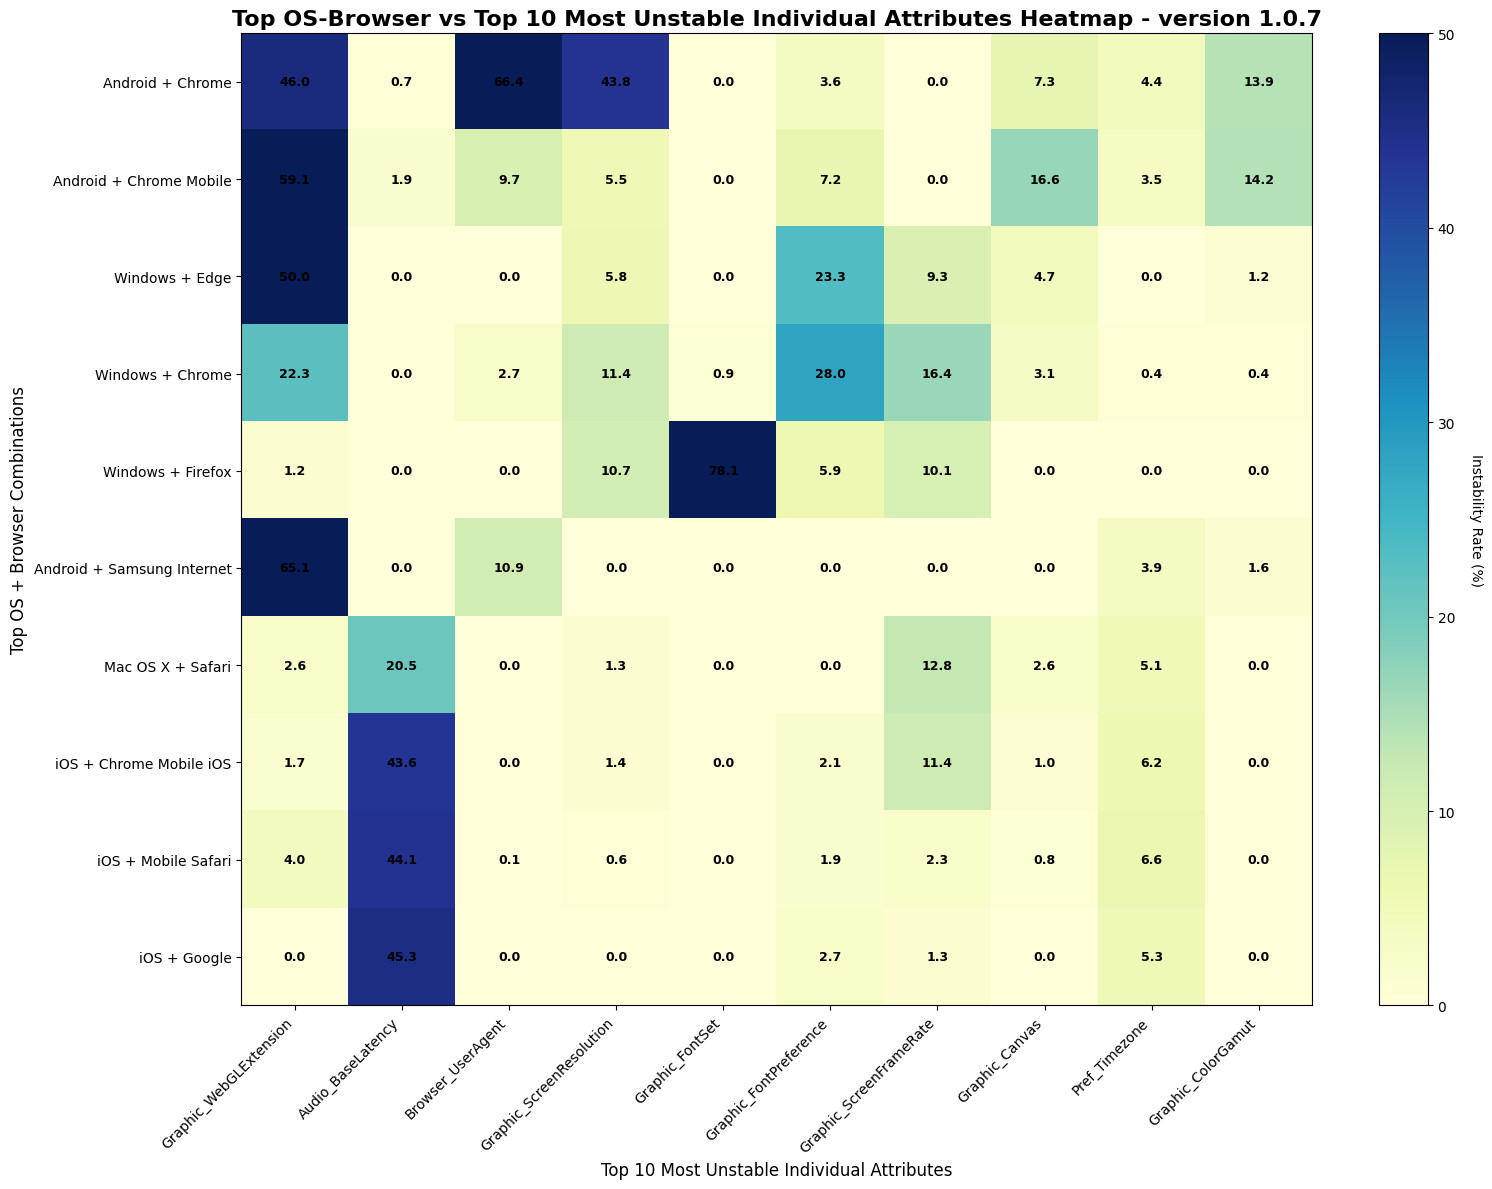

In [ ]:
# Chart: Top OS-Browser vs Top 10 Most Unstable Individual Attributes Heatmap (v7 Data - Expanded)
fig, ax = plt.subplots(figsize=(16, 12))

# Load data if not already loaded
if 'df' not in globals():
    df = pd.read_csv('sprint5/data/2nFP_Per_Device_v14.csv')

# Create df_expanded if not exists
if 'df_expanded' not in globals():
    print("Creating expanded dataset...")
    
    # Get OS and Browser columns
    os_col = df.columns[9]  # OS_List
    browser_col = df.columns[10]  # Browser_List
    
    # Create expanded dataset with individual OS-Browser combinations
    expanded_rows = []
    
    for idx, row in df.iterrows():
        device_id = row['DeviceCodeID']
        
        # Split OS values
        os_values = str(row[os_col]).split(',') if pd.notna(row[os_col]) else ['Unknown']
        os_values = [os.strip() for os in os_values if os.strip()]
        
        # Split Browser values  
        browser_values = str(row[browser_col]).split(',') if pd.notna(row[browser_col]) else ['Unknown']
        browser_values = [browser.strip() for browser in browser_values if browser.strip()]
        
        # Create all combinations of OS and Browser for this device
        for os_val in os_values:
            for browser_val in browser_values:
                expanded_row = row.copy()
                expanded_row['OS_Single'] = os_val
                expanded_row['Browser_Single'] = browser_val
                expanded_row['OS_Browser'] = f"{os_val} + {browser_val}"
                expanded_rows.append(expanded_row)
    
    # Create expanded DataFrame
    df_expanded = pd.DataFrame(expanded_rows)
    print(f"✅ Expanded dataset created: {len(df_expanded)} OS-Browser combinations")

# Define individual attribute mapping
attribute_mapping = {
    'Hardware_platformUniqueCount': 'Hardware_platform',
    'Hardware_cpuClassUniqueCount': 'Hardware_cpuClass',
    'Hardware_architectureUniqueCount': 'Hardware_architecture',
    'Hardware_hardwareConcurrencyUniqueCount': 'Hardware_hardwareConcurrency',
    'Hardware_oscpuUniqueCount': 'Hardware_oscpu',
    'Hardware_DeviceMemoryUniqueCount': 'Hardware_deviceMemory',
    'Graphic_CanvasUniqueCount': 'Graphic_canvas',
    'Graphic_WebGLBasicUniqueCount': 'Graphic_webglBasics',
    'Graphic_WebGLExtensionUniqueCount': 'Graphic_webglExtensions',
    'Graphic_FontSetUniqueCount': 'Graphic_fonts',
    'Graphic_FontPreferenceUniqueCount': 'Graphic_fontPreferences',
    'Graphic_ScreenResolutionUniqueCount': 'Graphic_screenResolution',
    'Graphic_ScreenFrameRateUniqueCount': 'Graphic_screenFrame',
    'Graphic_ColorDepthUniqueCount': 'Graphic_colorDepth',
    'Graphic_ColorGamutUniqueCount': 'Graphic_colorGamut',
    'Audio_ContextUniqueCount': 'Audio_audio',
    'Audio_BaseLatencyUniqueCount': 'Audio_audioBaseLatency',
    'Browser_NameUniqueCount': 'Browser_browserName',
    'Browser_OSNameUniqueCount': 'Browser_osName',
    'Browser_UserAgentUniqueCount': 'Browser_userAgent',
    'Browser_VendorUniqueCount': 'Browser_vendor',
    'Browser_VendorFlavorUniqueCount': 'Browser_vendorFlavor',
    'Browser_PluginUniqueCount': 'Browser_plugin',
    'Browser_PDFViewerUniqueCount': 'Browser_pdfViewer',
    'Pref_LanguageUniqueCount': 'Preferences_languages',
    'Pref_TimezoneUniqueCount': 'Preferences_timezone',
    'Pref_TouchSupportUniqueCount': 'Preferences_touchSupport',
    'Pref_SessionStorageUniqueCount': 'Preferences_sessionStorage',
    'Pref_OpenDatabaseUniqueCount': 'Preferences_openDatabase',
    'Pref_LocalStorageUniqueCount': 'Preferences_localStorage',
    'Pref_IndexedDBUniqueCount': 'Preferences_indexedDB',
    'Pref_CookiesEnabledUniqueCount': 'Preferences_cookiesEnabled'
}
attribute_columns_list = list(attribute_mapping.keys())

# Get top OS-Browser combinations by occurrence count (minimum 5 occurrences)
os_browser_counts = df_expanded['OS_Browser'].value_counts()
top_os_browser = os_browser_counts[os_browser_counts >= 5].head(10)  # Top 10 with at least 5 occurrences

print(f"Top OS-Browser combinations for individual attributes analysis (min 5 occurrences):")
for combo, count in top_os_browser.items():
    print(f"  {combo}: {count} occurrences")

# Calculate average individual attribute instability for top OS-Browser combinations only
individual_instability_by_os_browser = []

for os_browser in top_os_browser.index:
    subset = df_expanded[df_expanded['OS_Browser'] == os_browser]
    
    # Calculate average instability for each individual attribute
    attribute_stats = {}
    for attr_col in attribute_columns_list:
        # Count occurrences with instability (unique count > 1)
        unstable_occurrences = (subset[attr_col] > 1).sum()
        total_occurrences = len(subset)
        instability_rate = (unstable_occurrences / total_occurrences) * 100 if total_occurrences > 0 else 0
        attribute_stats[attr_col] = instability_rate
    
    individual_instability_by_os_browser.append({
        'OS_Browser': os_browser,
        **attribute_stats
    })

# Create DataFrame for heatmap
individual_heatmap_df = pd.DataFrame(individual_instability_by_os_browser)
individual_heatmap_df = individual_heatmap_df.set_index('OS_Browser')

# Sort by total instability
individual_heatmap_df['Total_Instability'] = individual_heatmap_df.sum(axis=1)
individual_heatmap_df = individual_heatmap_df.sort_values('Total_Instability', ascending=False)

# Find top 10 most unstable individual attributes across top combinations
attribute_totals = individual_heatmap_df.drop('Total_Instability', axis=1).sum(axis=0).sort_values(ascending=False)
top_10_attributes = attribute_totals.head(10).index.tolist()

# Select only top 10 attributes for plotting
plot_df = individual_heatmap_df[top_10_attributes]

# Create heatmap
im = ax.imshow(plot_df.values, cmap='YlGnBu', aspect='auto', vmin=0, vmax=50)

# Set labels
ax.set_yticks(range(len(plot_df.index)))
ax.set_yticklabels(plot_df.index, fontsize=10)
ax.set_xticks(range(len(plot_df.columns)))
ax.set_xticklabels([col.replace('UniqueCount', '') for col in plot_df.columns],
                   rotation=45, ha='right', fontsize=10)

# Add colorbar
cbar = plt.colorbar(im, ax=ax)
cbar.set_label('Instability Rate (%)', rotation=270, labelpad=20)

# Add text annotations
for i in range(len(plot_df.index)):
    for j in range(len(plot_df.columns)):
        value = plot_df.iloc[i, j]
        text = ax.text(j, i, f'{value:.1f}',
                      ha="center", va="center", color="black", fontsize=9, fontweight='bold')

ax.set_title('Top OS-Browser vs Top 10 Most Unstable Individual Attributes Heatmap - version 1.0.7', fontsize=16, fontweight='bold')
ax.set_xlabel('Top 10 Most Unstable Individual Attributes', fontsize=12)
ax.set_ylabel('Top OS + Browser Combinations', fontsize=12)
plt.tight_layout()
plt.show()


## Conclusion

This analysis validates the findings from the stability analysis report and provides comprehensive visualizations of device fingerprint attribute stability patterns using the v4 dataset. The data confirms:

1. **Hardware attributes** are the most reliable for device identification
2. **Graphic attributes** show concerning instability patterns
3. **Statistical validation** confirms the reported findings
4. **Clear recommendations** for fingerprinting strategy based on stability patterns

The visualizations and statistical analysis provide a solid foundation for making data-driven decisions about device fingerprinting implementation.
